# LQ45 Risk Management Dashboard

Proyek ini membangun dashboard analisis risiko menggunakan pendekatan CAPM, simulasi Monte Carlo, dan strategi hedging pada 45 saham konstituen LQ45, yaitu saham-saham dengan likuiditas dan kapitalisasi pasar tertinggi yang tercatat di Bursa Efek Indonesia.

Tahapan yang dilakukan:
1. **Data collection & cleaning** — download harga historis 45 saham LQ45 dan indeks pasar (IHSG)
2. **CAPM regression** — estimasi beta tiap saham terhadap pasar sebagai dasar pengukuran risiko sistematis
3. **Value at Risk (VaR) & Conditional VaR (CVaR)** — simulasi Monte Carlo untuk mengukur potensi kerugian portofolio pada tingkat kepercayaan tertentu
4. **Backtesting VaR** — validasi akurasi model VaR terhadap data historis (breach test)
5. **Hedging strategy** — konstruksi strategi *beta-neutral hedging* menggunakan estimasi beta dari CAPM
6. **Visualisasi & insight** — distribusi return, VaR/CVaR chart, dan perbandingan risiko sebelum-sesudah hedging

Output akhir adalah estimasi risiko portofolio (VaR/CVaR) beserta rekomendasi strategi hedging untuk menetralkan eksposur pasar.

## 1. Setup & Data Collection

Tahap pertama ini menyiapkan seluruh komponen dasar yang dibutuhkan sepanjang notebook: library, universe saham, rentang waktu, dan proses pengambilan data harga.

**Universe:** 45 saham konstituen Indeks LQ45 periode 3 Agustus – 30 Oktober 2026. LQ45 dipilih sebagai basis analisis karena berisi saham-saham dengan likuiditas dan kapitalisasi pasar tertinggi di BEI — kriteria yang penting untuk perhitungan VaR/CVaR dan strategi hedging yang realistis (asumsi mampu masuk/keluar posisi tanpa slippage besar).

**Proxy pasar:** Indeks IHSG (`^JKSE`) digunakan sebagai representasi pasar untuk regresi CAPM pada tahap selanjutnya (estimasi beta tiap saham terhadap pasar, yang menjadi dasar strategi *beta-neutral hedging*).

**Rentang waktu:** 2 tahun data harian (13 September 2024 – 13 September 2026), cukup panjang untuk menangkap variasi kondisi pasar (naik, turun, sideways) tanpa terlalu jauh dari kondisi pasar saat ini.

**Sumber data:** Yahoo Finance melalui `yfinance`, dengan harga *adjusted close* agar sudah memperhitungkan aksi korporasi (dividen, stock split).

In [2]:
# =============================================================
# SECTION 1: SETUP & DATA COLLECTION
# =============================================================

import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

# -------------------------------------------------------------
# 1.1 Universe: LQ45 constituents (periode 3 Agustus - 30 Oktober 2026)
# -------------------------------------------------------------
lq45_tickers = [
    'AADI', 'ADMR', 'ADRO', 'AKRA', 'AMMN', 'AMRT', 'ANTM', 'ASII',
    'BBCA', 'BBNI', 'BBRI', 'BBTN', 'BMRI', 'BRPT', 'BUMI', 'CPIN',
    'CUAN', 'DEWA', 'EMTK', 'ESSA', 'EXCL', 'GOTO', 'HRTA', 'ICBP',
    'INCO', 'INDF', 'INDY', 'INKP', 'ISAT', 'ITMG', 'JPFA', 'KLBF',
    'MAPI', 'MBMA', 'MDKA', 'MEDC', 'NCKL', 'PGAS', 'PGEO', 'PTBA',
    'SCMA', 'TLKM', 'UNTR', 'UNVR', 'WIFI'
]

# Yahoo Finance requires the .JK suffix for IDX-listed stocks
tickers_jk = [t + '.JK' for t in lq45_tickers]

# Market proxy for CAPM regression (IHSG / Jakarta Composite Index)
market_ticker = '^JKSE'

# -------------------------------------------------------------
# 1.2 Date range: 2 years of daily data
# -------------------------------------------------------------
end_date = datetime(2026, 9, 13)
start_date = datetime(2024, 9, 13)

print(f"Universe: {len(lq45_tickers)} saham LQ45")
print(f"Periode: {start_date.date()} s.d. {end_date.date()}")

# -------------------------------------------------------------
# 1.3 Download adjusted close prices — stocks + market index
# -------------------------------------------------------------
def download_prices(tickers, start, end):
    """Download adjusted close prices for a list of tickers."""
    raw = yf.download(tickers, start=start, end=end, auto_adjust=True, progress=False)
    prices = raw['Close'] if isinstance(raw.columns, pd.MultiIndex) else raw[['Close']]
    return prices

stock_prices = download_prices(tickers_jk, start_date, end_date)
market_prices = download_prices(market_ticker, start_date, end_date)

# Clean up column names (strip .JK suffix)
stock_prices.columns = [c.replace('.JK', '') for c in stock_prices.columns]

print(f"\nShape data saham: {stock_prices.shape}")
print(f"Shape data market: {market_prices.shape}")
stock_prices.head()

Universe: 45 saham LQ45
Periode: 2024-09-13 s.d. 2026-09-13

Shape data saham: (477, 45)
Shape data market: (472, 1)


,AADI,ADMR,ADRO,AKRA,AMMN,AMRT,ANTM,ASII,BBCA,BBNI,BBRI,BBTN,BMRI,BRPT,BUMI,CPIN,CUAN,DEWA,EMTK,ESSA,EXCL,GOTO,HRTA,ICBP,INCO,INDF,INDY,INKP,ISAT,ITMG,JPFA,KLBF,MAPI,MBMA,MDKA,MEDC,NCKL,PGAS,PGEO,PTBA,SCMA,TLKM,UNTR,UNVR,WIFI
Date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2024-09-13,NaN,1205.867310,1799.491821,1270.823486,10325.0,3015.155029,1184.981445,4362.543457,9541.244141,4751.662598,4388.714844,1345.817871,5951.605957,1138.748657,99.0,4485.879883,887.5,63.690323,382.207001,739.395508,2105.670898,61.0,364.694519,10635.350586,3553.659912,6569.344727,1488.128174,8214.149414,2488.006104,22167.884766,1340.824585,1619.772583,1635.671875,540.0,2278.924072,1132.786499,782.274902,1251.960571,1026.280151,2314.425293,97.807541,2665.575684,22692.521484,1880.620361,263.424500
2024-09-17,NaN,1238.333008,1843.621094,1279.468506,10275.0,3015.155029,1224.924561,4362.543457,9609.884766,4772.780273,4388.714844,1359.934814,6074.319336,1143.743286,105.0,4635.409180,890.0,65.680649,378.478149,739.395508,2078.442139,65.0,364.694519,10705.784180,3602.074951,6569.344727,1488.128174,8116.070801,2476.567383,21871.750000,1362.591309,1619.772583,1763.766724,540.0,2288.875732,1137.410156,791.318542,1251.960571,1026.280151,2373.769531,98.615868,2648.433838,22972.414062,1863.523682,279.389648
2024-09-18,NaN,1229.057007,1789.685303,1266.500977,10375.0,3024.726807,1211.610229,4512.976074,9724.288086,4815.017578,4430.117676,1397.580078,6053.867188,1138.748657,105.0,4616.718262,880.0,65.680649,387.800262,730.378479,2069.366211,61.0,362.804901,10799.694336,3563.343018,6546.212891,1463.243042,8165.110352,2442.250000,21935.208984,1345.178101,1662.523193,1773.620117,525.0,2268.972412,1137.410156,791.318542,1256.147705,1026.280151,2356.813965,96.999214,2674.146729,23015.472656,1889.168823,275.398346
2024-09-19,NaN,1261.522705,1794.588623,1270.823486,10425.0,2986.438965,1220.486572,4534.466309,9975.976562,4920.609863,4471.520508,1444.636597,6053.867188,1193.688354,117.0,4719.519531,885.0,67.670967,382.207001,721.361511,2087.518555,63.0,368.473724,10987.515625,3573.026123,6546.212891,1488.128174,8165.110352,2436.530518,21998.666016,1345.178101,1643.522949,1753.913208,530.0,2259.020752,1160.528076,791.318542,1239.399048,1030.861694,2356.813965,97.807541,2691.288818,22929.351562,1880.620361,277.394012
2024-09-20,NaN,1252.246826,1809.298462,1292.436157,10325.0,2986.438965,1216.048340,4491.485840,9861.572266,4857.254883,4450.819336,1439.931030,5972.058594,1063.831055,116.0,4672.791504,725.0,67.670967,367.291626,721.361511,2069.366211,63.0,368.473724,11269.247070,3582.708984,6615.607422,1463.243042,8067.030762,2436.530518,21914.056641,1358.238037,1634.022827,1822.887329,540.0,2249.069092,1169.775391,804.883972,1247.773315,1021.698486,2500.935791,98.615868,2699.859619,23187.710938,1854.975464,273.402710


## 2. Data Cleaning

Tahap ini memastikan data harga yang sudah didownload bebas dari missing values dan siap dipakai untuk perhitungan return. Data harga saham LQ45 dan IHSG digabung dalam satu dataframe agar perhitungan return market dan saham selalu sejajar tanggalnya, lalu baris dengan data kosong (misal karena hari libur bursa yang berbeda atau saham baru listing) dibersihkan.

Saham dengan data historis yang terlalu banyak bolong (di bawah threshold kelengkapan) di-drop dari universe agar tidak mendistorsi hasil regresi CAPM dan simulasi VaR selanjutnya.

In [3]:
# =============================================================
# SECTION 2: DATA CLEANING
# =============================================================

# -------------------------------------------------------------
# 2.1 Gabungkan harga saham dan market index dalam satu dataframe
# -------------------------------------------------------------
market_prices.columns = ['IHSG']
all_prices = pd.concat([stock_prices, market_prices], axis=1)

print(f"Shape sebelum cleaning: {all_prices.shape}")
print(f"\nJumlah missing values per kolom (top 10):")
print(all_prices.isna().sum().sort_values(ascending=False).head(10))

# -------------------------------------------------------------
# 2.2 Drop kolom (saham) dengan missing data terlalu banyak
# -------------------------------------------------------------
missing_threshold = 0.10  # drop saham dengan >10% data kosong
missing_pct = all_prices.isna().mean()
cols_to_drop = missing_pct[missing_pct > missing_threshold].index.tolist()

if cols_to_drop:
    print(f"\nSaham di-drop (missing > {missing_threshold*100:.0f}%): {cols_to_drop}")
    all_prices = all_prices.drop(columns=cols_to_drop)
    lq45_tickers = [t for t in lq45_tickers if t not in cols_to_drop]
else:
    print("\nTidak ada saham yang di-drop.")

# -------------------------------------------------------------
# 2.3 Forward-fill sisa missing values, lalu drop baris yang masih kosong
# -------------------------------------------------------------
all_prices = all_prices.ffill()
all_prices = all_prices.dropna()

print(f"\nShape setelah cleaning: {all_prices.shape}")
print(f"Rentang tanggal final: {all_prices.index.min().date()} s.d. {all_prices.index.max().date()}")

# Pisahkan kembali harga saham dan market index yang sudah bersih
market_prices_clean = all_prices[['IHSG']]
stock_prices_clean = all_prices.drop(columns=['IHSG'])

all_prices.head()

Shape sebelum cleaning: (477, 46)

Jumlah missing values per kolom (top 10):
AADI    58
IHSG     5
ADRO     1
DEWA     1
WIFI     1
PGEO     1
NCKL     1
MDKA     1
MBMA     1
INDY     1
dtype: int64

Saham di-drop (missing > 10%): ['AADI']

Shape setelah cleaning: (477, 45)
Rentang tanggal final: 2024-09-13 s.d. 2026-09-11


,ADMR,ADRO,AKRA,AMMN,AMRT,ANTM,ASII,BBCA,BBNI,BBRI,BBTN,BMRI,BRPT,BUMI,CPIN,CUAN,DEWA,EMTK,ESSA,EXCL,GOTO,HRTA,ICBP,INCO,INDF,INDY,INKP,ISAT,ITMG,JPFA,KLBF,MAPI,MBMA,MDKA,MEDC,NCKL,PGAS,PGEO,PTBA,SCMA,TLKM,UNTR,UNVR,WIFI,IHSG
Date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2024-09-13,1205.867310,1799.491821,1270.823486,10325.0,3015.155029,1184.981445,4362.543457,9541.244141,4751.662598,4388.714844,1345.817871,5951.605957,1138.748657,99.0,4485.879883,887.5,63.690323,382.207001,739.395508,2105.670898,61.0,364.694519,10635.350586,3553.659912,6569.344727,1488.128174,8214.149414,2488.006104,22167.884766,1340.824585,1619.772583,1635.671875,540.0,2278.924072,1132.786499,782.274902,1251.960571,1026.280151,2314.425293,97.807541,2665.575684,22692.521484,1880.620361,263.424500,7812.130859
2024-09-17,1238.333008,1843.621094,1279.468506,10275.0,3015.155029,1224.924561,4362.543457,9609.884766,4772.780273,4388.714844,1359.934814,6074.319336,1143.743286,105.0,4635.409180,890.0,65.680649,378.478149,739.395508,2078.442139,65.0,364.694519,10705.784180,3602.074951,6569.344727,1488.128174,8116.070801,2476.567383,21871.750000,1362.591309,1619.772583,1763.766724,540.0,2288.875732,1137.410156,791.318542,1251.960571,1026.280151,2373.769531,98.615868,2648.433838,22972.414062,1863.523682,279.389648,7831.778809
2024-09-18,1229.057007,1789.685303,1266.500977,10375.0,3024.726807,1211.610229,4512.976074,9724.288086,4815.017578,4430.117676,1397.580078,6053.867188,1138.748657,105.0,4616.718262,880.0,65.680649,387.800262,730.378479,2069.366211,61.0,362.804901,10799.694336,3563.343018,6546.212891,1463.243042,8165.110352,2442.250000,21935.208984,1345.178101,1662.523193,1773.620117,525.0,2268.972412,1137.410156,791.318542,1256.147705,1026.280151,2356.813965,96.999214,2674.146729,23015.472656,1889.168823,275.398346,7829.134766
2024-09-19,1261.522705,1794.588623,1270.823486,10425.0,2986.438965,1220.486572,4534.466309,9975.976562,4920.609863,4471.520508,1444.636597,6053.867188,1193.688354,117.0,4719.519531,885.0,67.670967,382.207001,721.361511,2087.518555,63.0,368.473724,10987.515625,3573.026123,6546.212891,1488.128174,8165.110352,2436.530518,21998.666016,1345.178101,1643.522949,1753.913208,530.0,2259.020752,1160.528076,791.318542,1239.399048,1030.861694,2356.813965,97.807541,2691.288818,22929.351562,1880.620361,277.394012,7905.390137
2024-09-20,1252.246826,1809.298462,1292.436157,10325.0,2986.438965,1216.048340,4491.485840,9861.572266,4857.254883,4450.819336,1439.931030,5972.058594,1063.831055,116.0,4672.791504,725.0,67.670967,367.291626,721.361511,2069.366211,63.0,368.473724,11269.247070,3582.708984,6615.607422,1463.243042,8067.030762,2436.530518,21914.056641,1358.238037,1634.022827,1822.887329,540.0,2249.069092,1169.775391,804.883972,1247.773315,1021.698486,2500.935791,98.615868,2699.859619,23187.710938,1854.975464,273.402710,7743.003906


## 3. CAPM Regression

Capital Asset Pricing Model (CAPM) digunakan untuk mengestimasi **beta** setiap saham — ukuran seberapa sensitif pergerakan return saham terhadap pergerakan return pasar (IHSG). Beta inilah yang nantinya jadi fondasi utama strategi *beta-neutral hedging* di Section 5.

Model regresi linear yang digunakan:

**R_saham = α + β × R_market + ε**

- **β (beta) > 1** → saham lebih volatil dibanding pasar (agresif)
- **β = 1** → saham bergerak sejalan dengan pasar
- **β < 1** → saham lebih defensif dibanding pasar
- **β < 0** → saham bergerak berlawanan arah dengan pasar (jarang terjadi, tapi berguna untuk diversifikasi/hedging)
- **α (alpha)** → return saham yang tidak dijelaskan oleh pergerakan pasar (excess return)

Regresi dilakukan per saham menggunakan `scipy.stats.linregress` terhadap return harian, lalu hasil beta, alpha, dan R² tiap saham dirangkum dalam satu tabel untuk dibandingkan.

Jumlah observasi return: 476
Ringkasan hasil regresi CAPM (diurutkan berdasarkan Beta):


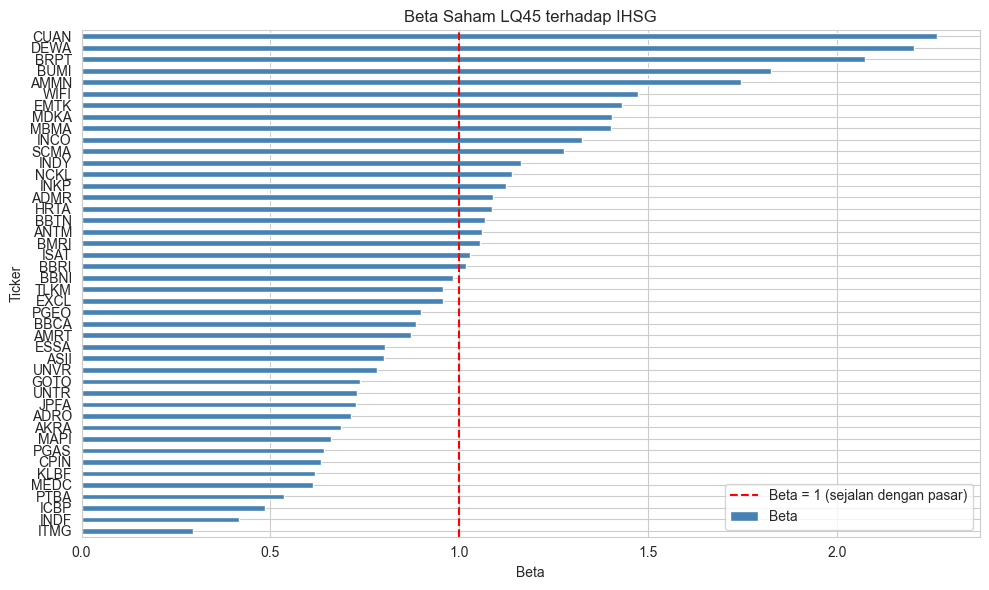


Top 5 saham beta tertinggi (paling agresif):
            Beta  R_squared
Ticker                     
CUAN    2.265018   0.319904
DEWA    2.202821   0.345917
BRPT    2.072804   0.375945
BUMI    1.824517   0.279443
AMMN    1.745845   0.348622

Top 5 saham beta terendah (paling defensif):
            Beta  R_squared
Ticker                     
MEDC    0.612169   0.088962
PTBA    0.534758   0.180372
ICBP    0.485973   0.143498
INDF    0.416121   0.108210
ITMG    0.296272   0.073713


In [4]:
# =============================================================
# SECTION 3: CAPM REGRESSION
# =============================================================

from scipy import stats

# -------------------------------------------------------------
# 3.1 Hitung return harian (log return) untuk saham dan market
# -------------------------------------------------------------
stock_returns = np.log(stock_prices_clean / stock_prices_clean.shift(1)).dropna()
market_returns = np.log(market_prices_clean / market_prices_clean.shift(1)).dropna()

# Samakan index (tanggal) antara stock_returns dan market_returns
common_dates = stock_returns.index.intersection(market_returns.index)
stock_returns = stock_returns.loc[common_dates]
market_returns = market_returns.loc[common_dates]

market_ret_series = market_returns['IHSG']

print(f"Jumlah observasi return: {len(common_dates)}")
stock_returns.head()

# -------------------------------------------------------------
# 3.2 Regresi CAPM per saham: R_saham = alpha + beta * R_market
# -------------------------------------------------------------
capm_results = []

for ticker in stock_returns.columns:
    slope, intercept, r_value, p_value, std_err = stats.linregress(
        market_ret_series, stock_returns[ticker]
    )
    capm_results.append({
        'Ticker': ticker,
        'Beta': slope,
        'Alpha': intercept,
        'R_squared': r_value ** 2,
        'P_value': p_value,
        'Std_Err': std_err
    })

capm_df = pd.DataFrame(capm_results).set_index('Ticker').sort_values('Beta', ascending=False)

print("Ringkasan hasil regresi CAPM (diurutkan berdasarkan Beta):")
capm_df.round(4)

# -------------------------------------------------------------
# 3.3 Visualisasi distribusi beta seluruh saham LQ45
# -------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6))
capm_df['Beta'].sort_values().plot(kind='barh', ax=ax, color='steelblue')
ax.axvline(x=1, color='red', linestyle='--', label='Beta = 1 (sejalan dengan pasar)')
ax.set_xlabel('Beta')
ax.set_title('Beta Saham LQ45 terhadap IHSG')
ax.legend()
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# 3.4 Highlight saham dengan beta tertinggi & terendah
# -------------------------------------------------------------
print("\nTop 5 saham beta tertinggi (paling agresif):")
print(capm_df.head(5)[['Beta', 'R_squared']])

print("\nTop 5 saham beta terendah (paling defensif):")
print(capm_df.tail(5)[['Beta', 'R_squared']])

## 4. Value at Risk (VaR) & Conditional VaR (CVaR) — Monte Carlo Simulation

Tahap ini mengukur potensi kerugian portofolio pada tingkat kepercayaan tertentu menggunakan simulasi Monte Carlo, berdasarkan karakteristik return dan risiko (volatilitas serta korelasi antar saham) yang sudah dihitung dari data historis.

**Value at Risk (VaR)** menjawab pertanyaan: "Dengan tingkat kepercayaan 95% (atau 99%), berapa kerugian maksimum yang mungkin dialami portofolio dalam periode tertentu (misal 1 hari)?"

**Conditional VaR (CVaR)**, atau disebut juga *Expected Shortfall*, melangkah lebih jauh: mengukur rata-rata kerugian **jika** kerugian tersebut melebihi ambang batas VaR. CVaR memberi gambaran seberapa parah kerugian di skenario ekor (*tail risk*) yang tidak ditangkap VaR.

Pendekatan yang digunakan:
1. Bentuk portofolio dengan bobot equal-weight sebagai baseline (44 saham LQ45)
2. Simulasikan 10.000 skenario return portofolio 1 hari ke depan menggunakan **Monte Carlo** — sampling dari distribusi normal multivariat berdasarkan mean return dan matriks kovarians historis
3. Hitung VaR dan CVaR pada tingkat kepercayaan 95% dan 99% dari hasil simulasi
4. Bandingkan dengan VaR historis (metode non-parametrik) sebagai sanity check

Return harian portofolio (rata-rata): 0.00038
Volatilitas harian portofolio: 0.01624
Rata-rata simulasi P&L: Rp 479,103
Std Dev simulasi P&L: Rp 16,246,337

--- Monte Carlo VaR/CVaR (horizon 1 hari, portofolio Rp 1,000,000,000) ---
VaR 95%:  Rp -26,311,053  (kerugian maksimum dengan keyakinan 95%)
CVaR 95%: Rp -33,145,144  (rata-rata kerugian jika melebihi VaR 95%)
VaR 99%:  Rp -37,349,222
CVaR 99%: Rp -42,407,167

--- Historical VaR/CVaR (sanity check) ---
VaR 95%:  Rp -24,178,371
CVaR 95%: Rp -40,972,894
VaR 99%:  Rp -50,176,883
CVaR 99%: Rp -67,253,796


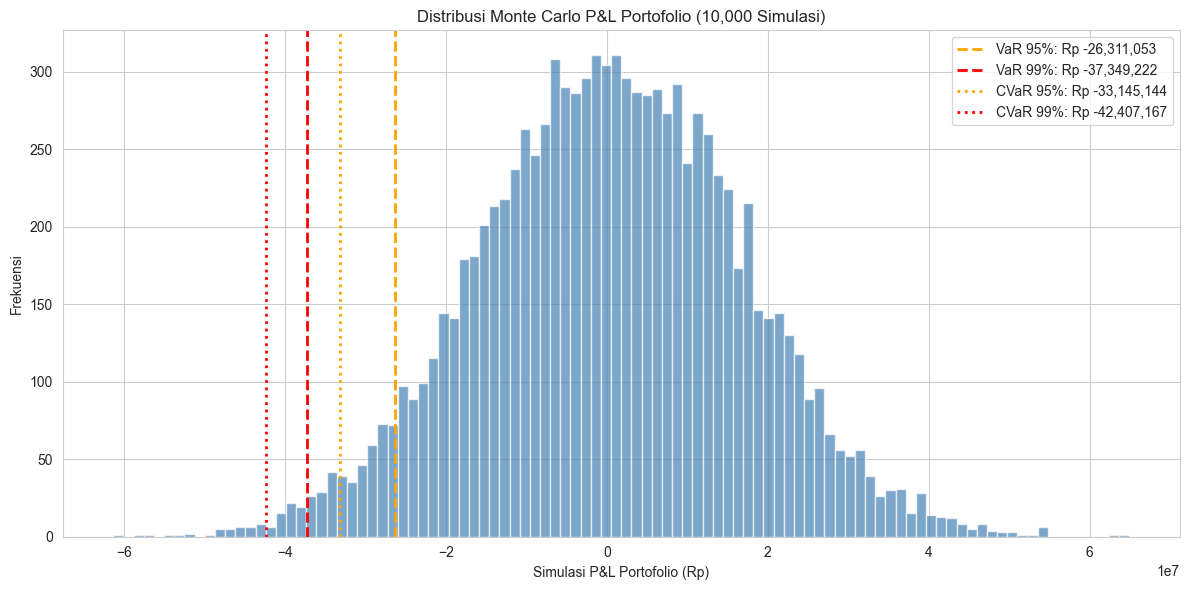

In [5]:
# =============================================================
# SECTION 4: VALUE AT RISK (VaR) & CONDITIONAL VaR (CVaR)
# =============================================================

# -------------------------------------------------------------
# 4.1 Bentuk portofolio equal-weight sebagai baseline
# -------------------------------------------------------------
n_assets = len(stock_returns.columns)
weights = np.array([1 / n_assets] * n_assets)

portfolio_value = 1_000_000_000  # asumsi nilai portofolio Rp 1 miliar

mean_returns = stock_returns.mean()
cov_matrix = stock_returns.cov()

portfolio_mean = np.dot(weights, mean_returns)
portfolio_std = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))

print(f"Return harian portofolio (rata-rata): {portfolio_mean:.5f}")
print(f"Volatilitas harian portofolio: {portfolio_std:.5f}")

# -------------------------------------------------------------
# 4.2 Monte Carlo simulation — 10,000 skenario return 1 hari ke depan
# -------------------------------------------------------------
n_simulations = 10_000
np.random.seed(42)

# Sampling return multivariat berdasarkan mean & kovarians historis
simulated_returns = np.random.multivariate_normal(
    mean_returns, cov_matrix, n_simulations
)

# Return portofolio per simulasi (weighted sum)
simulated_portfolio_returns = simulated_returns @ weights

# Konversi ke potensi kerugian/keuntungan dalam Rupiah
simulated_pnl = simulated_portfolio_returns * portfolio_value

print(f"Rata-rata simulasi P&L: Rp {simulated_pnl.mean():,.0f}")
print(f"Std Dev simulasi P&L: Rp {simulated_pnl.std():,.0f}")

# -------------------------------------------------------------
# 4.3 Hitung VaR dan CVaR (95% dan 99%) dari hasil simulasi
# -------------------------------------------------------------
def calculate_var_cvar(pnl_array, confidence_level):
    var_threshold = np.percentile(pnl_array, (1 - confidence_level) * 100)
    cvar = pnl_array[pnl_array <= var_threshold].mean()
    return var_threshold, cvar

var_95, cvar_95 = calculate_var_cvar(simulated_pnl, 0.95)
var_99, cvar_99 = calculate_var_cvar(simulated_pnl, 0.99)

print(f"\n--- Monte Carlo VaR/CVaR (horizon 1 hari, portofolio Rp {portfolio_value:,.0f}) ---")
print(f"VaR 95%:  Rp {var_95:,.0f}  (kerugian maksimum dengan keyakinan 95%)")
print(f"CVaR 95%: Rp {cvar_95:,.0f}  (rata-rata kerugian jika melebihi VaR 95%)")
print(f"VaR 99%:  Rp {var_99:,.0f}")
print(f"CVaR 99%: Rp {cvar_99:,.0f}")

# -------------------------------------------------------------
# 4.4 Bandingkan dengan VaR historis (non-parametrik) sebagai sanity check
# -------------------------------------------------------------
historical_portfolio_returns = stock_returns @ weights
historical_pnl = historical_portfolio_returns * portfolio_value

hist_var_95, hist_cvar_95 = calculate_var_cvar(historical_pnl, 0.95)
hist_var_99, hist_cvar_99 = calculate_var_cvar(historical_pnl, 0.99)

print(f"\n--- Historical VaR/CVaR (sanity check) ---")
print(f"VaR 95%:  Rp {hist_var_95:,.0f}")
print(f"CVaR 95%: Rp {hist_cvar_95:,.0f}")
print(f"VaR 99%:  Rp {hist_var_99:,.0f}")
print(f"CVaR 99%: Rp {hist_cvar_99:,.0f}")

# -------------------------------------------------------------
# 4.5 Visualisasi distribusi hasil simulasi Monte Carlo
# -------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 6))
ax.hist(simulated_pnl, bins=100, color='steelblue', alpha=0.7, edgecolor='white')
ax.axvline(var_95, color='orange', linestyle='--', linewidth=2, label=f'VaR 95%: Rp {var_95:,.0f}')
ax.axvline(var_99, color='red', linestyle='--', linewidth=2, label=f'VaR 99%: Rp {var_99:,.0f}')
ax.axvline(cvar_95, color='orange', linestyle=':', linewidth=2, label=f'CVaR 95%: Rp {cvar_95:,.0f}')
ax.axvline(cvar_99, color='red', linestyle=':', linewidth=2, label=f'CVaR 99%: Rp {cvar_99:,.0f}')
ax.set_xlabel('Simulasi P&L Portofolio (Rp)')
ax.set_ylabel('Frekuensi')
ax.set_title('Distribusi Monte Carlo P&L Portofolio (10,000 Simulasi)')
ax.legend()
plt.tight_layout()
plt.show()

## 5. Backtesting VaR

Model VaR yang bagus di atas kertas belum tentu akurat di dunia nyata — karena itu perlu **backtesting**: menguji seberapa sering kerugian aktual historis benar-benar melebihi (breach) estimasi VaR yang dihasilkan model.

Pendekatan yang digunakan:
1. **Rolling VaR (historical method)** — hitung VaR 95% dan 99% menggunakan rolling window 250 hari (kira-kira 1 tahun trading), lalu geser window-nya setiap hari untuk membentuk rangkaian estimasi VaR dari waktu ke waktu
2. **Breach counting** — bandingkan return portofolio aktual di hari berikutnya (di luar window) terhadap estimasi VaR saat itu; hitung berapa kali kerugian aktual melebihi VaR (disebut *breach* atau *exception*)
3. **Kupiec's Proportion of Failures (POF) Test** — uji statistik formal untuk memastikan apakah jumlah breach yang terjadi konsisten secara statistik dengan tingkat kepercayaan yang diklaim model (misal: VaR 95% seharusnya di-breach ~5% dari waktu, bukan jauh lebih sering atau lebih jarang)

Kalau jumlah breach jauh melebihi ekspektasi teoritis, model VaR dianggap **terlalu optimis** (meremehkan risiko). Kalau jauh lebih sedikit dari ekspektasi, model dianggap **terlalu konservatif**.

Jumlah observasi backtest: 227

--- VaR 95% ---
Breach: 16 kali (7.05%) | Ekspektasi teoritis: 5.00%

--- VaR 99% ---
Breach: 3 kali (1.32%) | Ekspektasi teoritis: 1.00%

--- Kupiec POF Test ---
VaR 95%: LR statistic = 1.789, p-value = 0.181 (Model VALID pada alpha 5%)
VaR 99%: LR statistic = 0.215, p-value = 0.643 (Model VALID pada alpha 5%)


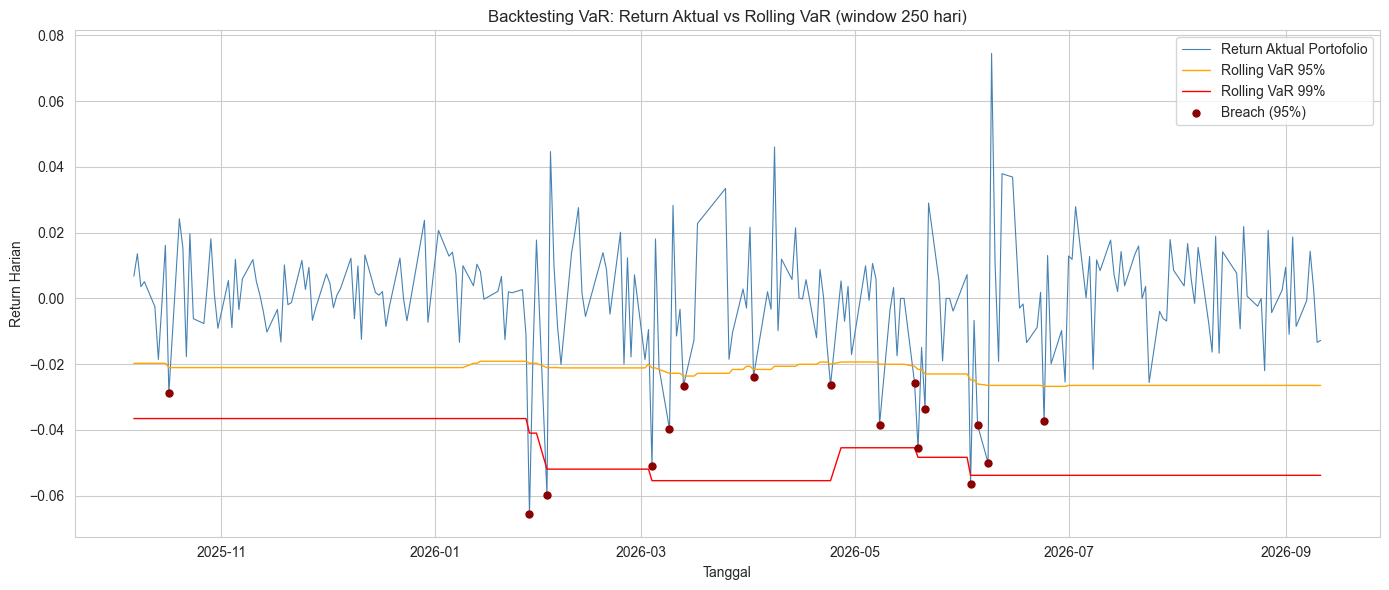

Detail 16 hari breach VaR 95% (portofolio Rp 1,000,000,000):



,Actual_Return,VaR_95,Actual_PnL_Rp,VaR_95_Threshold_Rp,Selisih_vs_VaR_Rp
Date,,,,,
2025-10-17,-0.03,-0.02,-28736343.11,-21036813.83,-7699529.28
2026-01-28,-0.07,-0.02,-65478513.18,-19728074.24,-45750438.94
2026-02-02,-0.06,-0.02,-59769123.07,-21036813.83,-38732309.24
2026-03-04,-0.05,-0.02,-50910525.33,-21131507.21,-29779018.12
2026-03-09,-0.04,-0.02,-39708031.44,-22779664.60,-16928366.84
2026-03-13,-0.03,-0.02,-26560373.82,-23609208.72,-2951165.09
2026-04-02,-0.02,-0.02,-23764248.36,-21594562.71,-2169685.65
2026-04-24,-0.03,-0.02,-26331481.17,-20024304.00,-6307177.17
2026-05-08,-0.04,-0.02,-38347039.70,-20024304.00,-18322735.70


In [7]:
# =============================================================
# SECTION 5: BACKTESTING VaR
# =============================================================

from scipy.stats import chi2

# -------------------------------------------------------------
# 5.1 Rolling historical VaR (window 250 hari) + actual portfolio return
# -------------------------------------------------------------
window = 250
portfolio_returns_series = stock_returns @ weights  # return harian portofolio equal-weight

rolling_var_95 = portfolio_returns_series.rolling(window).quantile(0.05)
rolling_var_99 = portfolio_returns_series.rolling(window).quantile(0.01)

backtest_df = pd.DataFrame({
    'Actual_Return': portfolio_returns_series,
    'VaR_95': rolling_var_95,
    'VaR_99': rolling_var_99
}).dropna()

# -------------------------------------------------------------
# 5.2 Breach counting: actual return < VaR threshold hari itu
# -------------------------------------------------------------
backtest_df['Breach_95'] = backtest_df['Actual_Return'] < backtest_df['VaR_95']
backtest_df['Breach_99'] = backtest_df['Actual_Return'] < backtest_df['VaR_99']

n_obs = len(backtest_df)
n_breach_95 = backtest_df['Breach_95'].sum()
n_breach_99 = backtest_df['Breach_99'].sum()

breach_rate_95 = n_breach_95 / n_obs
breach_rate_99 = n_breach_99 / n_obs

print(f"Jumlah observasi backtest: {n_obs}")
print(f"\n--- VaR 95% ---")
print(f"Breach: {n_breach_95} kali ({breach_rate_95:.2%}) | Ekspektasi teoritis: 5.00%")
print(f"\n--- VaR 99% ---")
print(f"Breach: {n_breach_99} kali ({breach_rate_99:.2%}) | Ekspektasi teoritis: 1.00%")

# -------------------------------------------------------------
# 5.3 Kupiec's Proportion of Failures (POF) Test
# -------------------------------------------------------------
def kupiec_pof_test(n_breaches, n_obs, confidence_level):
    """Kupiec likelihood ratio test untuk validasi VaR breach rate."""
    p = 1 - confidence_level  # expected breach probability
    p_hat = n_breaches / n_obs

    if n_breaches == 0:
        lr_stat = -2 * n_obs * np.log(1 - p)
    else:
        lr_stat = -2 * (
            n_breaches * np.log(p / p_hat) + (n_obs - n_breaches) * np.log((1 - p) / (1 - p_hat))
        )

    p_value = 1 - chi2.cdf(lr_stat, df=1)
    return lr_stat, p_value

lr_95, pval_95 = kupiec_pof_test(n_breach_95, n_obs, 0.95)
lr_99, pval_99 = kupiec_pof_test(n_breach_99, n_obs, 0.99)

print(f"\n--- Kupiec POF Test ---")
print(f"VaR 95%: LR statistic = {lr_95:.3f}, p-value = {pval_95:.3f} "
      f"({'Model VALID' if pval_95 > 0.05 else 'Model DITOLAK'} pada alpha 5%)")
print(f"VaR 99%: LR statistic = {lr_99:.3f}, p-value = {pval_99:.3f} "
      f"({'Model VALID' if pval_99 > 0.05 else 'Model DITOLAK'} pada alpha 5%)")

# -------------------------------------------------------------
# 5.4 Visualisasi: actual return vs rolling VaR, breach ditandai
# -------------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(backtest_df.index, backtest_df['Actual_Return'], color='steelblue', linewidth=0.8, label='Return Aktual Portofolio')
ax.plot(backtest_df.index, backtest_df['VaR_95'], color='orange', linewidth=1, label='Rolling VaR 95%')
ax.plot(backtest_df.index, backtest_df['VaR_99'], color='red', linewidth=1, label='Rolling VaR 99%')

breach_points_95 = backtest_df[backtest_df['Breach_95']]
ax.scatter(breach_points_95.index, breach_points_95['Actual_Return'], color='darkred', s=25, zorder=5, label='Breach (95%)')

ax.set_xlabel('Tanggal')
ax.set_ylabel('Return Harian')
ax.set_title('Backtesting VaR: Return Aktual vs Rolling VaR (window 250 hari)')
ax.legend()
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# 5.5 Tabel detail hari-hari breach (95%) dengan estimasi kerugian rupiah
# -------------------------------------------------------------
breach_detail_95 = backtest_df[backtest_df['Breach_95']].copy()

breach_detail_95['Actual_PnL_Rp'] = breach_detail_95['Actual_Return'] * portfolio_value
breach_detail_95['VaR_95_Threshold_Rp'] = breach_detail_95['VaR_95'] * portfolio_value
breach_detail_95['Selisih_vs_VaR_Rp'] = breach_detail_95['Actual_PnL_Rp'] - breach_detail_95['VaR_95_Threshold_Rp']

display_cols = ['Actual_Return', 'VaR_95', 'Actual_PnL_Rp', 'VaR_95_Threshold_Rp', 'Selisih_vs_VaR_Rp']
breach_table = breach_detail_95[display_cols].round(2)

print(f"Detail {len(breach_table)} hari breach VaR 95% (portofolio Rp {portfolio_value:,.0f}):\n")
breach_table

## 6. Hedging Strategy — Beta-Neutral Hedging

Setelah mengetahui profil risiko portofolio (VaR/CVaR) dan eksposur sistematis tiap saham (beta dari CAPM di Section 3), tahap ini membangun strategi **beta-neutral hedging** — teknik untuk menetralkan eksposur portofolio terhadap pergerakan pasar secara keseluruhan, tanpa harus menjual saham-saham yang dipegang.

**Konsep dasar:** Portofolio dengan beta gabungan positif akan ikut naik/turun mengikuti arah IHSG. Untuk menetralkannya, kita **short** instrumen yang mengikuti pasar (dalam praktiknya: index futures IHSG, atau proxy ETF) dengan jumlah yang disesuaikan agar beta gabungan seluruh posisi (long saham + short index) mendekati nol.

**Rumus hedge ratio:**

**Notional short index = Beta Portofolio × Nilai Portofolio**

Kalau portofolio benar-benar *beta-neutral* (beta ≈ 0), maka secara teori pergerakan IHSG tidak lagi mempengaruhi nilai portofolio — risiko yang tersisa murni risiko spesifik saham (idiosyncratic risk), bukan risiko pasar (systematic risk).

Untuk menguji efektivitas strategi ini, kita bandingkan VaR/CVaR portofolio **sebelum** dan **sesudah** hedging menggunakan simulasi Monte Carlo yang sama seperti Section 4.

Beta Portofolio (equal-weight, 44 saham): 1.0382
Interpretasi: portofolio ini 1.04x lebih volatil dibanding IHSG

Nilai portofolio: Rp 1,000,000,000
Notional short index yang dibutuhkan: Rp 1,038,247,997

Rata-rata simulasi P&L SEBELUM hedging (joint): Rp 213,259
Std Dev simulasi P&L SEBELUM hedging (joint): Rp 16,499,598

Rata-rata simulasi P&L SESUDAH hedging: Rp 825,110
Std Dev simulasi P&L SESUDAH hedging: Rp 6,784,088

--- Perbandingan VaR/CVaR: Sebelum vs Sesudah Beta-Neutral Hedging ---


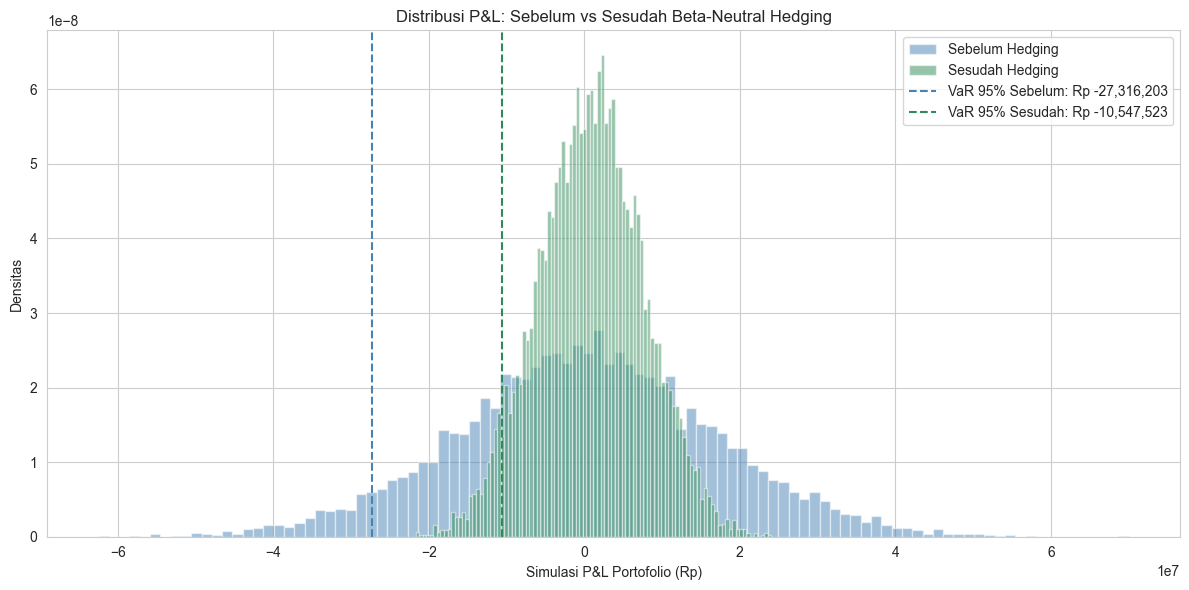

In [9]:
# =============================================================
# SECTION 6: HEDGING STRATEGY — BETA-NEUTRAL HEDGING (REVISI)
# =============================================================

# -------------------------------------------------------------
# 6.1 Hitung beta portofolio (weighted average dari beta CAPM tiap saham)
# -------------------------------------------------------------
portfolio_beta = np.dot(weights, capm_df.loc[stock_returns.columns, 'Beta'])

print(f"Beta Portofolio (equal-weight, 44 saham): {portfolio_beta:.4f}")
print(f"Interpretasi: portofolio ini {portfolio_beta:.2f}x lebih volatil dibanding IHSG")

# -------------------------------------------------------------
# 6.2 Hitung notional hedge yang dibutuhkan untuk beta-neutral
# -------------------------------------------------------------
hedge_notional = portfolio_beta * portfolio_value
hedge_ratio = portfolio_beta

print(f"\nNilai portofolio: Rp {portfolio_value:,.0f}")
print(f"Notional short index yang dibutuhkan: Rp {hedge_notional:,.0f}")

# -------------------------------------------------------------
# 6.3 Simulasi bersama (joint) saham + market — supaya korelasi terjaga
# -------------------------------------------------------------
# Gabungkan return saham dan market jadi satu set data untuk hitung covariance bersama
combined_returns = pd.concat([stock_returns, market_returns], axis=1)
combined_mean = combined_returns.mean()
combined_cov = combined_returns.cov()

np.random.seed(42)
simulated_combined = np.random.multivariate_normal(combined_mean, combined_cov, n_simulations)

# Pisahkan hasil simulasi: kolom saham vs kolom market (IHSG ada di kolom terakhir)
simulated_stocks_joint = simulated_combined[:, :-1]
simulated_market_joint = simulated_combined[:, -1]

# Return portofolio (sebelum hedging) dari simulasi joint ini
simulated_portfolio_returns_joint = simulated_stocks_joint @ weights
simulated_pnl_joint = simulated_portfolio_returns_joint * portfolio_value

# Return portofolio SETELAH hedging = return portofolio - hedge_ratio * return market
simulated_hedged_returns = simulated_portfolio_returns_joint - hedge_ratio * simulated_market_joint
simulated_hedged_pnl = simulated_hedged_returns * portfolio_value

print(f"\nRata-rata simulasi P&L SEBELUM hedging (joint): Rp {simulated_pnl_joint.mean():,.0f}")
print(f"Std Dev simulasi P&L SEBELUM hedging (joint): Rp {simulated_pnl_joint.std():,.0f}")
print(f"\nRata-rata simulasi P&L SESUDAH hedging: Rp {simulated_hedged_pnl.mean():,.0f}")
print(f"Std Dev simulasi P&L SESUDAH hedging: Rp {simulated_hedged_pnl.std():,.0f}")

# -------------------------------------------------------------
# 6.4 Bandingkan VaR/CVaR sebelum vs sesudah hedging (pakai simulasi joint yang konsisten)
# -------------------------------------------------------------
var_95_joint, cvar_95_joint = calculate_var_cvar(simulated_pnl_joint, 0.95)
var_99_joint, cvar_99_joint = calculate_var_cvar(simulated_pnl_joint, 0.99)
hedged_var_95, hedged_cvar_95 = calculate_var_cvar(simulated_hedged_pnl, 0.95)
hedged_var_99, hedged_cvar_99 = calculate_var_cvar(simulated_hedged_pnl, 0.99)

comparison_df = pd.DataFrame({
    'Sebelum Hedging': [var_95_joint, cvar_95_joint, var_99_joint, cvar_99_joint],
    'Sesudah Hedging': [hedged_var_95, hedged_cvar_95, hedged_var_99, hedged_cvar_99]
}, index=['VaR 95%', 'CVaR 95%', 'VaR 99%', 'CVaR 99%'])

comparison_df['Reduksi Risiko (%)'] = (
    (comparison_df['Sebelum Hedging'] - comparison_df['Sesudah Hedging'])
    / comparison_df['Sebelum Hedging'].abs() * 100
)

print("\n--- Perbandingan VaR/CVaR: Sebelum vs Sesudah Beta-Neutral Hedging ---")
comparison_df.round(0)

# -------------------------------------------------------------
# 6.5 Visualisasi distribusi P&L: sebelum vs sesudah hedging
# -------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 6))
ax.hist(simulated_pnl_joint, bins=100, alpha=0.5, color='steelblue', label='Sebelum Hedging', density=True)
ax.hist(simulated_hedged_pnl, bins=100, alpha=0.5, color='seagreen', label='Sesudah Hedging', density=True)
ax.axvline(var_95_joint, color='steelblue', linestyle='--', linewidth=1.5, label=f'VaR 95% Sebelum: Rp {var_95_joint:,.0f}')
ax.axvline(hedged_var_95, color='seagreen', linestyle='--', linewidth=1.5, label=f'VaR 95% Sesudah: Rp {hedged_var_95:,.0f}')
ax.set_xlabel('Simulasi P&L Portofolio (Rp)')
ax.set_ylabel('Densitas')
ax.set_title('Distribusi P&L: Sebelum vs Sesudah Beta-Neutral Hedging')
ax.legend()
plt.tight_layout()
plt.show()

## 7. Insight & Kesimpulan

### Ringkasan Temuan Utama

**1. Profil Risiko Sistematis (CAPM)**
Dari 44 saham LQ45 yang dianalisis, terdapat rentang beta yang lebar — dari saham paling agresif (CUAN, DEWA, BRPT dengan beta ~2.0–2.3) hingga paling defensif (ITMG, INDF, ICBP dengan beta ~0.3–0.5). Portofolio equal-weight dari seluruh 44 saham menghasilkan beta gabungan 1.0382 — hampir identik dengan pasar, konsisten dengan sifat LQ45 sebagai representasi mayoritas pergerakan IHSG.

**2. VaR/CVaR: Monte Carlo vs Historis**
Simulasi Monte Carlo (asumsi distribusi normal) menghasilkan estimasi risiko yang **lebih optimis** dibanding data historis riil, terutama di level kepercayaan 99% (CVaR Monte Carlo Rp -42,4 juta vs historis Rp -67,3 juta). Ini mengonfirmasi keterbatasan klasik model VaR berbasis distribusi normal: return saham riil memiliki *fat tails* — kejadian ekstrem lebih sering terjadi daripada yang diprediksi kurva normal.

**3. Backtesting Memvalidasi Model, dengan Catatan**
Uji Kupiec POF menunjukkan model VaR 95% dan 99% masih **valid secara statistik** (p-value > 0.05), meski breach rate aktual (7.05% dan 1.32%) sedikit di atas ekspektasi teoritis (5% dan 1%). Breach juga tidak tersebar acak — mengelompok di periode tertentu (Feb–Mar 2026), mengindikasikan *volatility clustering*, fenomena umum di pasar keuangan yang tidak ditangkap asumsi return independen.

**4. Hedging Efektif Menetralkan Risiko Pasar**
Strategi beta-neutral hedging (short index sebesar ~1.04x nilai portofolio) berhasil menurunkan volatilitas portofolio sebesar ~59% dan VaR 95% sebesar ~61%. Ini menunjukkan bahwa mayoritas risiko portofolio LQ45 equal-weight berasal dari eksposur pasar (*systematic risk*), bukan risiko spesifik saham individual — masuk akal mengingat beta portofolio yang mendekati 1.

### Limitasi

- **Asumsi distribusi normal** pada simulasi Monte Carlo tidak menangkap fat tails dan skewness yang terlihat jelas di data historis — untuk pekerjaan lanjutan, distribusi t-Student atau simulasi historis bootstrap bisa memberi estimasi ekor yang lebih realistis.
- **Beta dan korelasi diasumsikan statis** sepanjang periode data (2 tahun), padahal pada praktiknya beta bisa berubah seiring waktu (time-varying beta) — model seperti rolling beta atau GARCH bisa menangkap dinamika ini dengan lebih baik.
- **Portofolio equal-weight** dipakai sebagai baseline sederhana; bobot optimal ala Markowitz (seperti di project sebelumnya) belum diintegrasikan ke dalam analisis risiko ini.
- **Biaya transaksi dan slippage** dari eksekusi hedging (short index) tidak diperhitungkan — di dunia nyata ini akan mengurangi efektivitas hedging yang ditunjukkan di sini.
- **Instrumen hedging riil** (index futures IHSG) punya karakteristik kontrak spesifik (margin, roll-over, tick size) yang disederhanakan menjadi asumsi short langsung pada indeks di notebook ini.